# 🔍 ESPCN Super-Resolution Inference

Upscale every image of a benchmark set (**Set5** by default) with a trained **ESPCN** model at **×2, ×3, ×4 and ×5**, compare it against bicubic interpolation, and evaluate the results with four image-quality metrics. Results are reported **per image** and **averaged over the whole set**.

| Metric | Type | Direction | Notes |
|:--|:--|:--:|:--|
| **PSNR** | Full-reference | ⬆️ higher is better | BT.601 Y channel (16–235), borders shaved |
| **SSIM** | Full-reference | ⬆️ higher is better | BT.601 Y channel (16–235), borders shaved |
| **LPIPS** | Full-reference | ⬇️ lower is better | Perceptual distance, computed on RGB |
| **NIQE** | No-reference | ⬇️ lower is better | Computed on the super-resolved output only |

> **How it works:** each image of the set is treated as the high-resolution ground truth. It is downscaled with bicubic interpolation, passed through ESPCN, and the result is compared with the original.

## 1. Install dependencies

Internet access must be enabled in the Kaggle notebook settings.

In [1]:
!pip -q install pyiqa scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 9.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.3/226.3 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 112.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jesucristo/super-resolution-benchmarks")

print("Path to dataset files:", path)

path = kagglehub.model_download("amiraliabedi97/espcn-adam/pyTorch/x2")
path = kagglehub.model_download("amiraliabedi97/espcn-adam/pyTorch/x3")
path = kagglehub.model_download("amiraliabedi97/espcn-adam/pyTorch/x4")
path = kagglehub.model_download("amiraliabedi97/espcn-adam/pyTorch/x5")
print("Path to model files:", path)

Path to dataset files: /kaggle/input/datasets/jesucristo/super-resolution-benchmarks
Path to model files: /kaggle/input/models/amiraliabedi97/espcn-adam/pytorch/x5/1


## 2. Imports and configuration

Set `DATASET_ROOT`, `SET_NAME` and the checkpoint path for each scale. Scales whose checkpoint is missing are skipped. `VISUAL_IMAGE` is a part of an image file name to show in the visual comparison (`None` shows the first image).

In [3]:
import os
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import pyiqa

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATASET_ROOT = "/kaggle/input/datasets/jesucristo/super-resolution-benchmarks"
SET_NAME = "Set5"
VISUAL_IMAGE = 'butterfly'

WEIGHTS = {
    2: "/kaggle/input/models/amiraliabedi97/espcn-adam/pytorch/x2/1/tanh_seed42.pth",
    3: "/kaggle/input/models/amiraliabedi97/espcn-adam/pytorch/x3/1/tanh_seed42.pth",
    4: "/kaggle/input/models/amiraliabedi97/espcn-adam/pytorch/x4/1/tanh_seed42.pth",
    5: "/kaggle/input/models/amiraliabedi97/espcn-adam/pytorch/x5/1/tanh_seed42.pth",
}

Device: cuda


## 3. Model definition

Standard ESPCN: two feature-extraction convolutions followed by a sub-pixel convolution layer (`PixelShuffle`).

> ⚠️ If your architecture differs (channel counts, kernel sizes, activations), replace this class with your own so that the checkpoint keys match.

In [4]:
class ESPCN(nn.Module):
    def __init__(self, scale, in_ch=1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, 64, 5, padding=2),
            nn.Tanh(),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.Tanh(),
            nn.Conv2d(32, in_ch * scale ** 2, 3, padding=1),
        )
        self.shuffle = nn.PixelShuffle(scale)

    def forward(self, x):
        return self.shuffle(self.body(x))


def load_model(scale):
    path = WEIGHTS.get(scale, "")
    if not path or not os.path.exists(path):
        return None
    model = ESPCN(scale).to(device)
    ckpt = torch.load(path, map_location=device)
    if isinstance(ckpt, dict) and "state_dict" in ckpt:
        ckpt = ckpt["state_dict"]
    if isinstance(ckpt, dict) and "model" in ckpt:
        ckpt = ckpt["model"]
    model.load_state_dict(ckpt)
    return model.eval()

## 4. Helper functions

All color handling follows **ITU-R BT.601 studio-swing YCbCr** (the same transform as MATLAB `rgb2ycbcr`):

- **Y** is limited to **16–235**, **Cb/Cr** to **16–240**.
- `espcn_upscale` runs the network on the BT.601 **Y channel** (`Y / 255`), clips the output to **16–235**, and upsamples **Cb/Cr** with bicubic interpolation.
- `psnr_ssim_y` computes PSNR and SSIM on the BT.601 Y channel after shaving `scale` pixels from each border.

> If your model was trained with a different Y normalization (for example `(Y - 16) / 219`), change the two lines marked in `espcn_upscale` accordingly.

In [5]:
Y_MIN, Y_MAX = 16.0, 235.0
C_MIN, C_MAX = 16.0, 240.0

BT601_M = np.array([
    [65.481, 128.553, 24.966],
    [-37.797, -74.203, 112.0],
    [112.0, -93.786, -18.214],
])
BT601_OFFSET = np.array([16.0, 128.0, 128.0])
BT601_M_INV = np.linalg.inv(BT601_M)


def rgb_to_ycbcr_bt601(rgb_uint8):
    rgb = rgb_uint8.astype(np.float64) / 255.0
    return rgb @ BT601_M.T + BT601_OFFSET


def ycbcr_bt601_to_rgb(ycbcr):
    rgb = (ycbcr - BT601_OFFSET) @ BT601_M_INV.T
    return np.clip(np.round(rgb * 255.0), 0, 255).astype(np.uint8)


@torch.no_grad()
def espcn_upscale(model, lr_img, scale):
    ycbcr = rgb_to_ycbcr_bt601(np.asarray(lr_img))
    y_in = ycbcr[..., 0] / 255.0
    y_t = torch.from_numpy(y_in).float()[None, None].to(device)
    y_out = model(y_t)[0, 0].cpu().numpy().astype(np.float64) * 255.0
    y_sr = np.round(np.clip(y_out, Y_MIN, Y_MAX))

    h, w = y_sr.shape
    chroma = []
    for c in (1, 2):
        ch = Image.fromarray(np.round(ycbcr[..., c]).astype(np.uint8))
        ch = np.asarray(ch.resize((w, h), Image.BICUBIC), dtype=np.float64)
        chroma.append(np.clip(ch, C_MIN, C_MAX))

    sr_ycbcr = np.stack([y_sr, chroma[0], chroma[1]], axis=-1)
    return Image.fromarray(ycbcr_bt601_to_rgb(sr_ycbcr))


def rgb_to_y(img):
    return np.round(rgb_to_ycbcr_bt601(np.asarray(img))[..., 0])


def psnr_ssim_y(sr, hr, shave):
    a, b = rgb_to_y(sr), rgb_to_y(hr)
    if shave > 0:
        a = a[shave:-shave, shave:-shave]
        b = b[shave:-shave, shave:-shave]
    psnr = peak_signal_noise_ratio(b, a, data_range=255)
    ssim = structural_similarity(b, a, data_range=255)
    return psnr, ssim


def pil_to_tensor01(img):
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1)[None].to(device)

## 5. Build the metrics

LPIPS and NIQE are provided by [`pyiqa`](https://github.com/chaofengc/IQA-PyTorch). Pretrained weights are downloaded automatically on first use.

In [6]:
lpips_metric = pyiqa.create_metric("lpips", device=device)
niqe_metric = pyiqa.create_metric("niqe", device=device)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 185MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/LPIPS_v0.1_alex-df73285e.pth" to /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth



100%|██████████| 5.87k/5.87k [00:00<00:00, 24.7kB/s]


Loading pretrained model LPIPS from /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 18.4MB/s]


## 6. Run inference and evaluation on the whole set

The script first finds the HR images of the set (the `original` folder if there is one, otherwise the `HR`/`GT` files, and never the LR or bicubic copies) and prints them so you can verify the list. Then, for every image and every scale, it crops the image so its size is divisible by the scale, creates the low-resolution input, upscales it with both ESPCN and bicubic, and records all metrics.

In [7]:
SCALES = [2, 3, 4, 5]
IMAGE_EXTS = (".png", ".jpg", ".jpeg", ".bmp")
LR_PATTERN = re.compile(r"(^|[_\-.])(lr|bicubic|srf|x\d+)([_\-.]|$)")
HR_PATTERN = re.compile(r"(^|[_\-.])(hr|gt)([_\-.]|$)")


def find_hr_images(root, set_name):
    paths = []
    for dirpath, _, files in os.walk(root):
        rel_dir = os.path.relpath(dirpath, root).lower()
        if set_name.lower() not in rel_dir:
            continue
        for f in sorted(files):
            if f.lower().endswith(IMAGE_EXTS):
                paths.append(os.path.join(dirpath, f))

    originals = [p for p in paths if "original" in os.path.relpath(p, root).lower()]
    if originals:
        return sorted(originals)

    hr_files = [p for p in paths if HR_PATTERN.search(os.path.basename(p).lower())]
    if hr_files:
        first_dir = os.path.dirname(sorted(hr_files)[0])
        return sorted(p for p in hr_files if os.path.dirname(p) == first_dir)

    return sorted(p for p in paths if not LR_PATTERN.search(os.path.basename(p).lower()))


image_paths = find_hr_images(DATASET_ROOT, SET_NAME)
assert image_paths, f"No images found for {SET_NAME} under {DATASET_ROOT}"
print(f"{len(image_paths)} images found for {SET_NAME}:")
for p in image_paths:
    print("  ", os.path.relpath(p, DATASET_ROOT))

models = {s: load_model(s) for s in SCALES}
models = {s: m for s, m in models.items() if m is not None}
missing = [s for s in SCALES if s not in models]
if missing:
    print("Checkpoint not found, skipping scales:", missing)

visual_path = next(
    (p for p in image_paths if VISUAL_IMAGE and VISUAL_IMAGE.lower() in os.path.basename(p).lower()),
    image_paths[0],
)

rows, hr_rows, visuals = [], [], []

for path in image_paths:
    name = os.path.splitext(os.path.basename(path))[0]
    hr_full = Image.open(path).convert("RGB")

    with torch.no_grad():
        hr_niqe = niqe_metric(pil_to_tensor01(hr_full)).item()
    hr_rows.append({"Image": name, "HR NIQE": hr_niqe})

    for s, model in models.items():
        w, h = hr_full.size
        w, h = w - w % s, h - h % s
        hr = hr_full.crop((0, 0, w, h))
        lr = hr.resize((w // s, h // s), Image.BICUBIC)

        sr = espcn_upscale(model, lr, s)
        bicubic = lr.resize((w, h), Image.BICUBIC)

        for method, img in [("ESPCN", sr), ("Bicubic", bicubic)]:
            psnr, ssim = psnr_ssim_y(img, hr, shave=s)
            with torch.no_grad():
                lp = lpips_metric(pil_to_tensor01(img), pil_to_tensor01(hr)).item()
                nq = niqe_metric(pil_to_tensor01(img)).item()
            rows.append({
                "Image": name,
                "Scale": f"x{s}",
                "Method": method,
                "PSNR (dB) ↑": psnr,
                "SSIM ↑": ssim,
                "LPIPS ↓": lp,
                "NIQE ↓": nq,
            })

        if path == visual_path:
            visuals.append((s, lr, bicubic, sr, hr, name))

METRICS = ["PSNR (dB) ↑", "SSIM ↑", "LPIPS ↓", "NIQE ↓"]

per_image = pd.DataFrame(rows)
summary = per_image.groupby(["Scale", "Method"], sort=False)[METRICS].mean().reset_index()

print(f"Mean HR NIQE over {SET_NAME}: {pd.DataFrame(hr_rows)['HR NIQE'].mean():.3f}")
summary.round(4)

5 images found for Set5:
   Set5/Set5/original/baby.png
   Set5/Set5/original/bird.png
   Set5/Set5/original/butterfly.png
   Set5/Set5/original/head.png
   Set5/Set5/original/woman.png
Mean HR NIQE over Set5: 5.156


,Scale,Method,PSNR (dB) ↑,SSIM ↑,LPIPS ↓,NIQE ↓
0,x2,ESPCN,36.1483,0.9558,0.0660,6.0334
1,x2,Bicubic,33.6381,0.9359,0.1271,6.1296
2,x3,ESPCN,32.2696,0.9106,0.1577,7.4236
3,x3,Bicubic,30.3850,0.8796,0.2531,8.4812
4,x4,ESPCN,30.0582,0.8609,0.2481,7.7162
5,x4,Bicubic,28.4167,0.8221,0.3397,8.2849
6,x5,ESPCN,28.4169,0.8109,0.3235,8.8081
7,x5,Bicubic,26.9842,0.7683,0.4034,10.1212


## 7. Results table (mean over the set)

Each value is the **average over all images of the set**. The best value per metric is highlighted **separately within each scale** (ESPCN vs Bicubic). To disable coloring entirely, delete the `.apply(...)` line below.

In [8]:
HIGHER_BETTER = ["PSNR (dB) ↑", "SSIM ↑"]
LOWER_BETTER = ["LPIPS ↓", "NIQE ↓"]


def highlight_best_per_scale(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    for _, group in df.groupby("Scale"):
        for col in HIGHER_BETTER:
            styles.loc[group[col].idxmax(), col] = "background-color: #c8f7c5"
        for col in LOWER_BETTER:
            styles.loc[group[col].idxmin(), col] = "background-color: #c8f7c5"
    return styles


if len(summary):
    styled = (
        summary.style
        .format({
            "PSNR (dB) ↑": "{:.3f}",
            "SSIM ↑": "{:.4f}",
            "LPIPS ↓": "{:.4f}",
            "NIQE ↓": "{:.3f}",
        })
        .apply(highlight_best_per_scale, axis=None)
        .hide(axis="index")
    )
    display(styled)

Scale,Method,PSNR (dB) ↑,SSIM ↑,LPIPS ↓,NIQE ↓
x2,ESPCN,36.148,0.9558,0.0660,6.033
x2,Bicubic,33.638,0.9359,0.1271,6.130
x3,ESPCN,32.270,0.9106,0.1577,7.424
x3,Bicubic,30.385,0.8796,0.2531,8.481
x4,ESPCN,30.058,0.8609,0.2481,7.716
x4,Bicubic,28.417,0.8221,0.3397,8.285
x5,ESPCN,28.417,0.8109,0.3235,8.808
x5,Bicubic,26.984,0.7683,0.4034,10.121


## 8. Per-image results

The same metrics for every image and scale, before averaging.

In [9]:
per_image.round(4)

,Image,Scale,Method,PSNR (dB) ↑,SSIM ↑,LPIPS ↓,NIQE ↓
0,baby,x2,ESPCN,38.3683,0.9693,0.0921,4.4719
1,baby,x2,Bicubic,37.0268,0.9581,0.1368,4.8726
2,baby,x3,ESPCN,35.1066,0.9333,0.1774,6.2663
3,baby,x3,Bicubic,33.9016,0.9150,0.2431,7.0264
4,baby,x4,ESPCN,33.1088,0.8944,0.2489,6.1893
5,baby,x4,Bicubic,31.7674,0.8665,0.3031,7.2379
6,baby,x5,ESPCN,31.5118,0.8518,0.2954,6.4621
7,baby,x5,Bicubic,30.1558,0.8186,0.3544,8.6711
8,bird,x2,ESPCN,39.8200,0.9849,0.0154,5.7040
9,bird,x2,Bicubic,36.7691,0.9750,0.0563,5.9649


## 9. Visual comparison

Each row shows, from left to right: the low-resolution input, bicubic upscaling, ESPCN output, and the original high-resolution image. Only one image of the set is shown (see `VISUAL_IMAGE`).

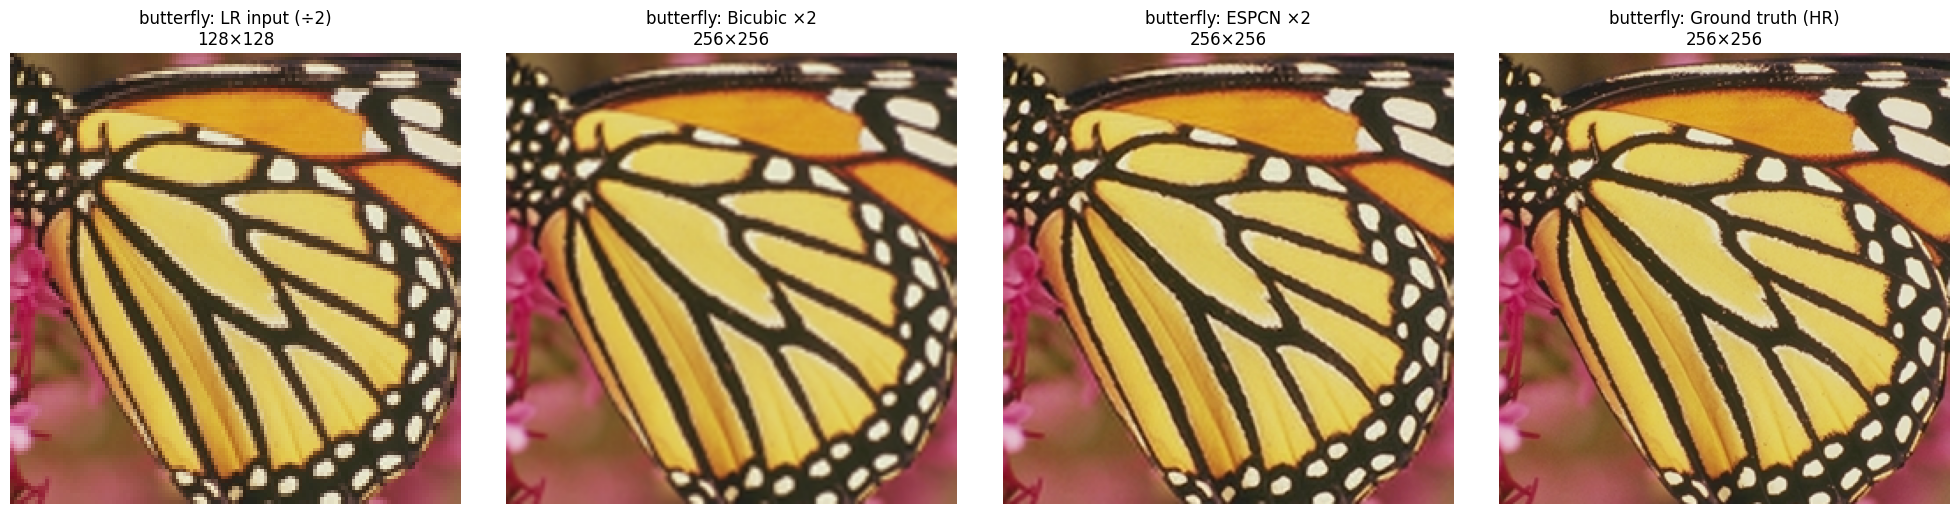

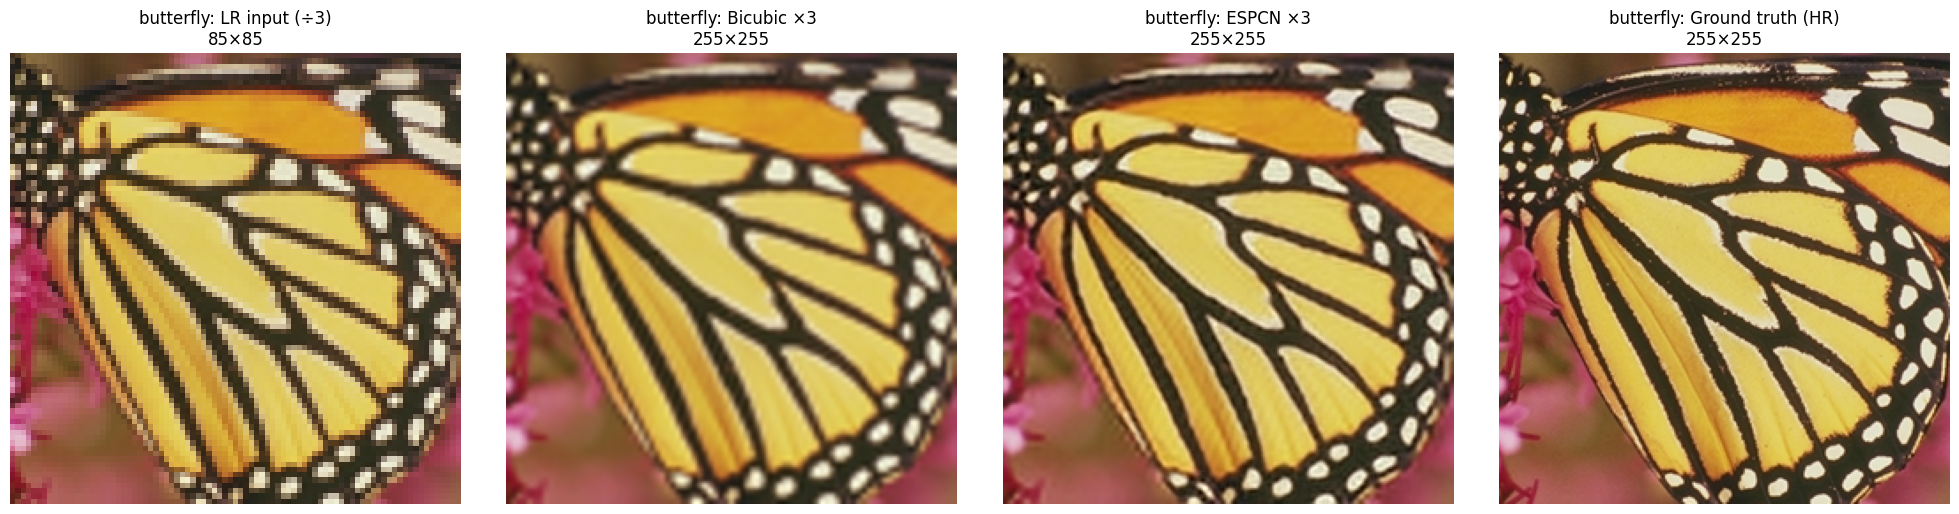

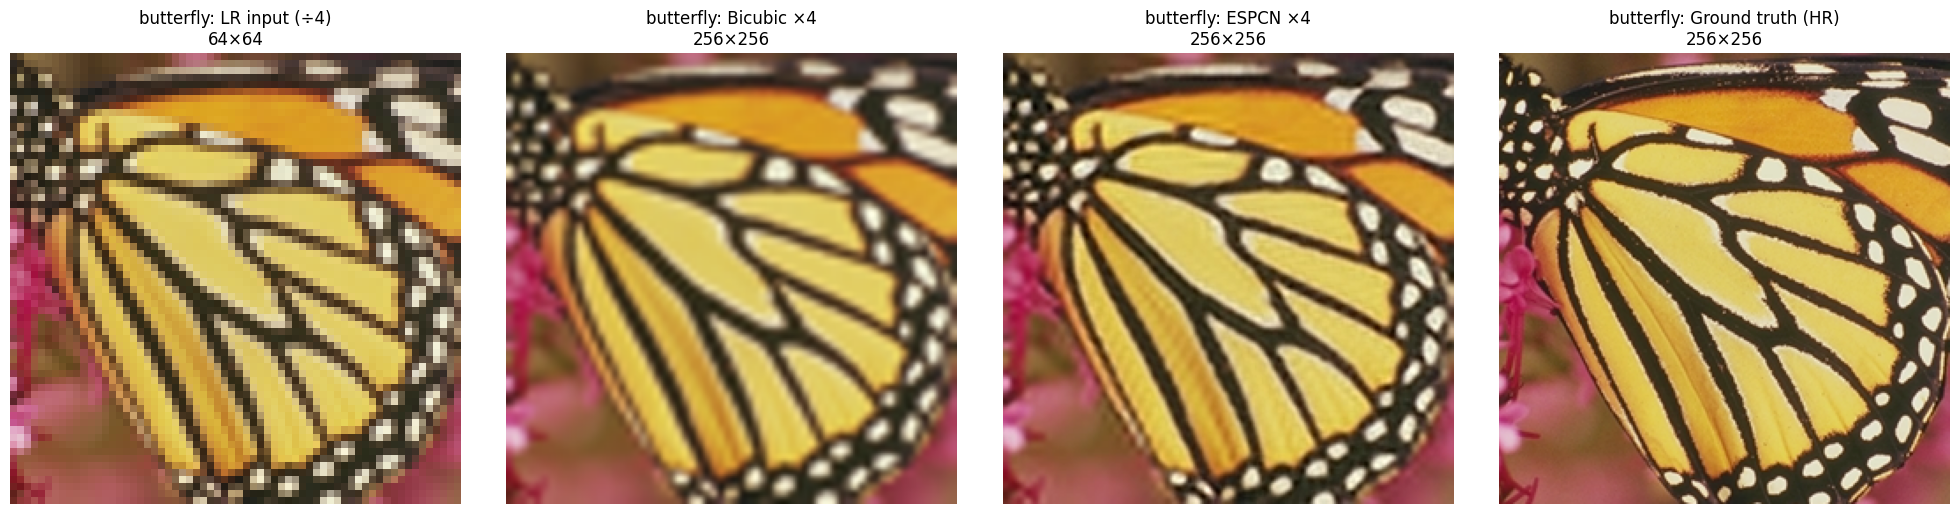

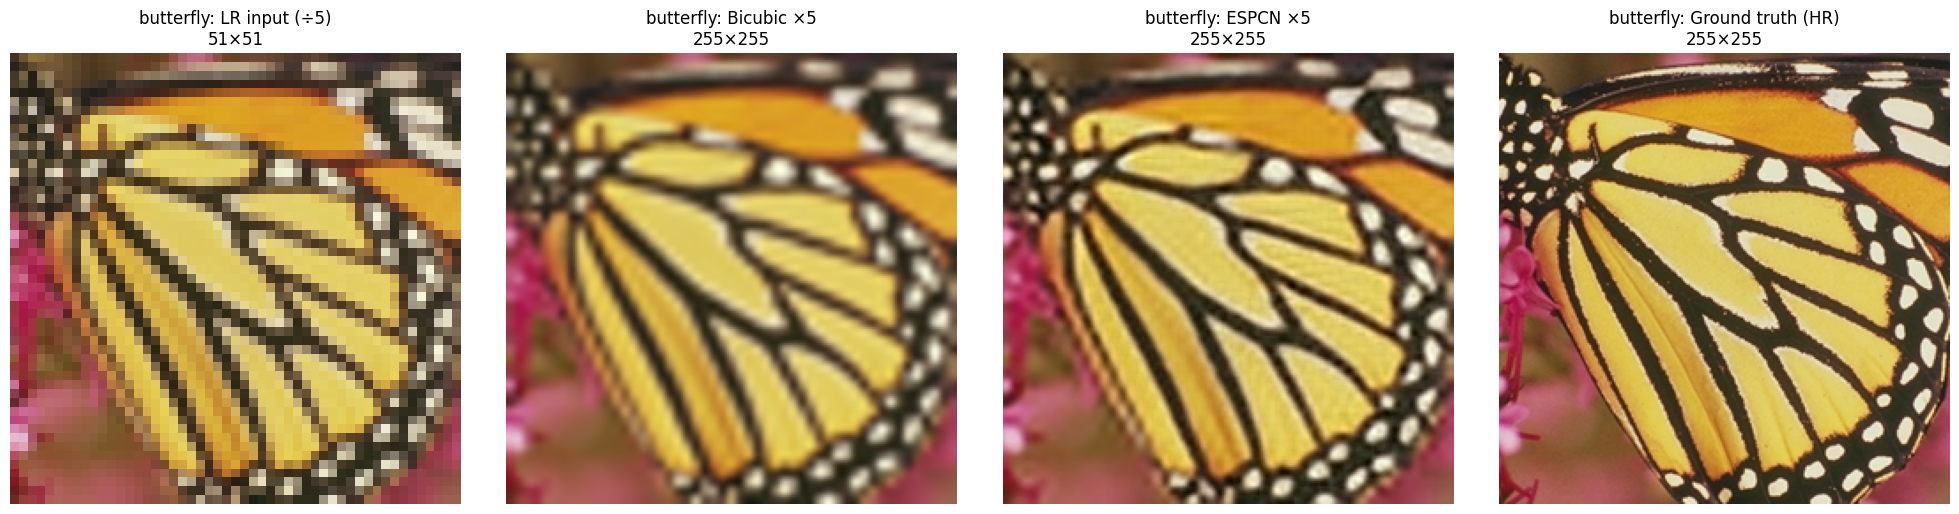

In [10]:
for s, lr, bicubic, sr, hr, name in visuals:
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    items = [
        (lr, f"LR input (÷{s})"),
        (bicubic, f"Bicubic ×{s}"),
        (sr, f"ESPCN ×{s}"),
        (hr, "Ground truth (HR)"),
    ]
    for ax, (im, title) in zip(axes, items):
        ax.imshow(im)
        ax.set_title(f"{name}: {title}\n{im.size[0]}×{im.size[1]}", fontsize=12)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 10. Zoomed patch comparison

Pick one image and a rectangle, and compare that region at full detail across all scales: the **LR input** (nearest-neighbor enlarged), **Bicubic**, **ESPCN** and the **ground truth**. The first panel shows the whole image with the chosen rectangle in red.

- `PATCH_IMAGE`: part of an image file name (`None` uses the first image of the set).
- `PATCH_BOX`: `(left, top, width, height)` in HR pixels, or `None` to automatically pick the most detailed region of size `PATCH_SIZE`.
- For each scale the box is snapped to a multiple of that scale, so the LR patch and the HR patches cover exactly the same region.
- The patch PSNR (on the BT.601 Y channel) is shown in the titles of Bicubic and ESPCN.

Image: butterfly | box (left, top, width, height): (150, 50, 60, 60)


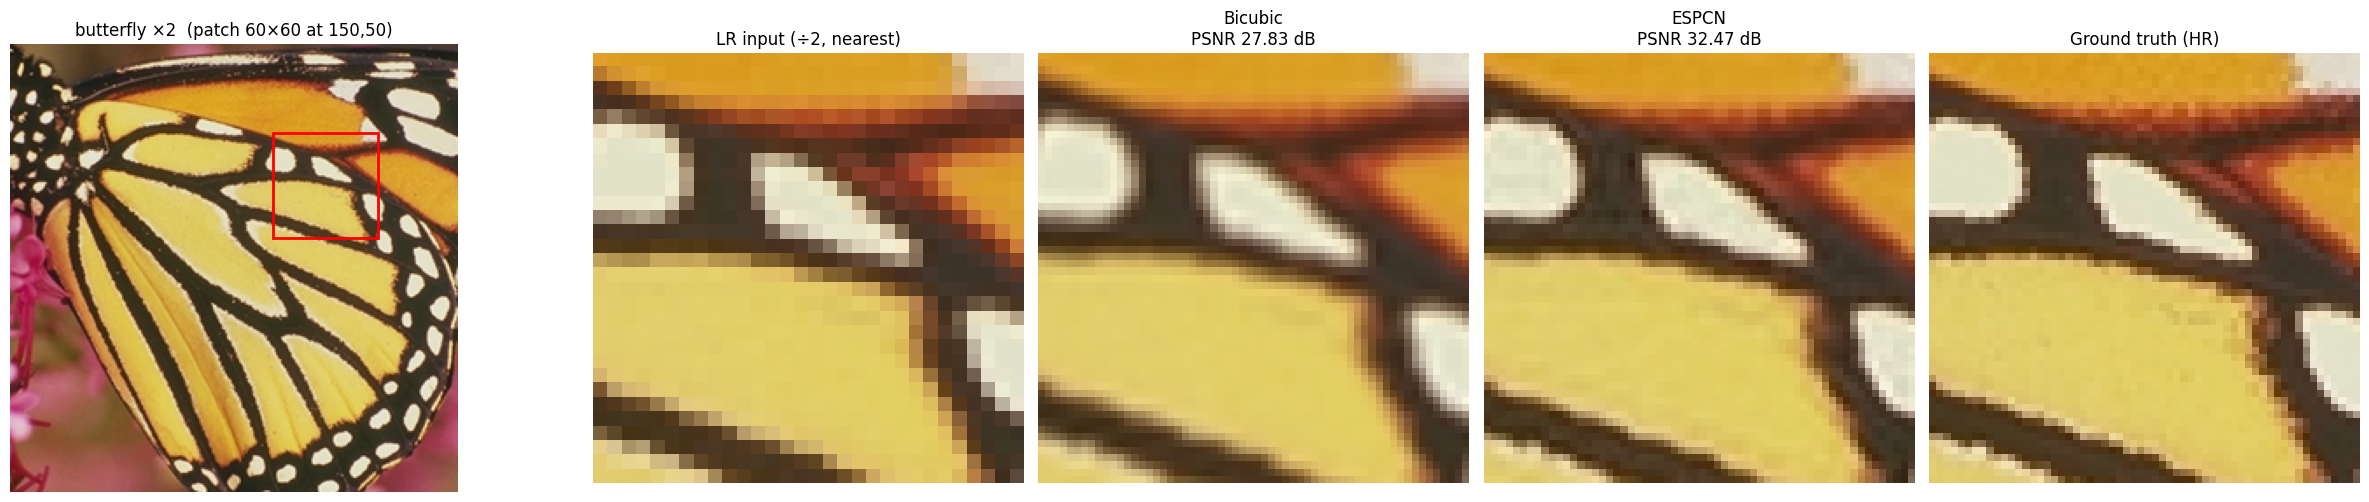

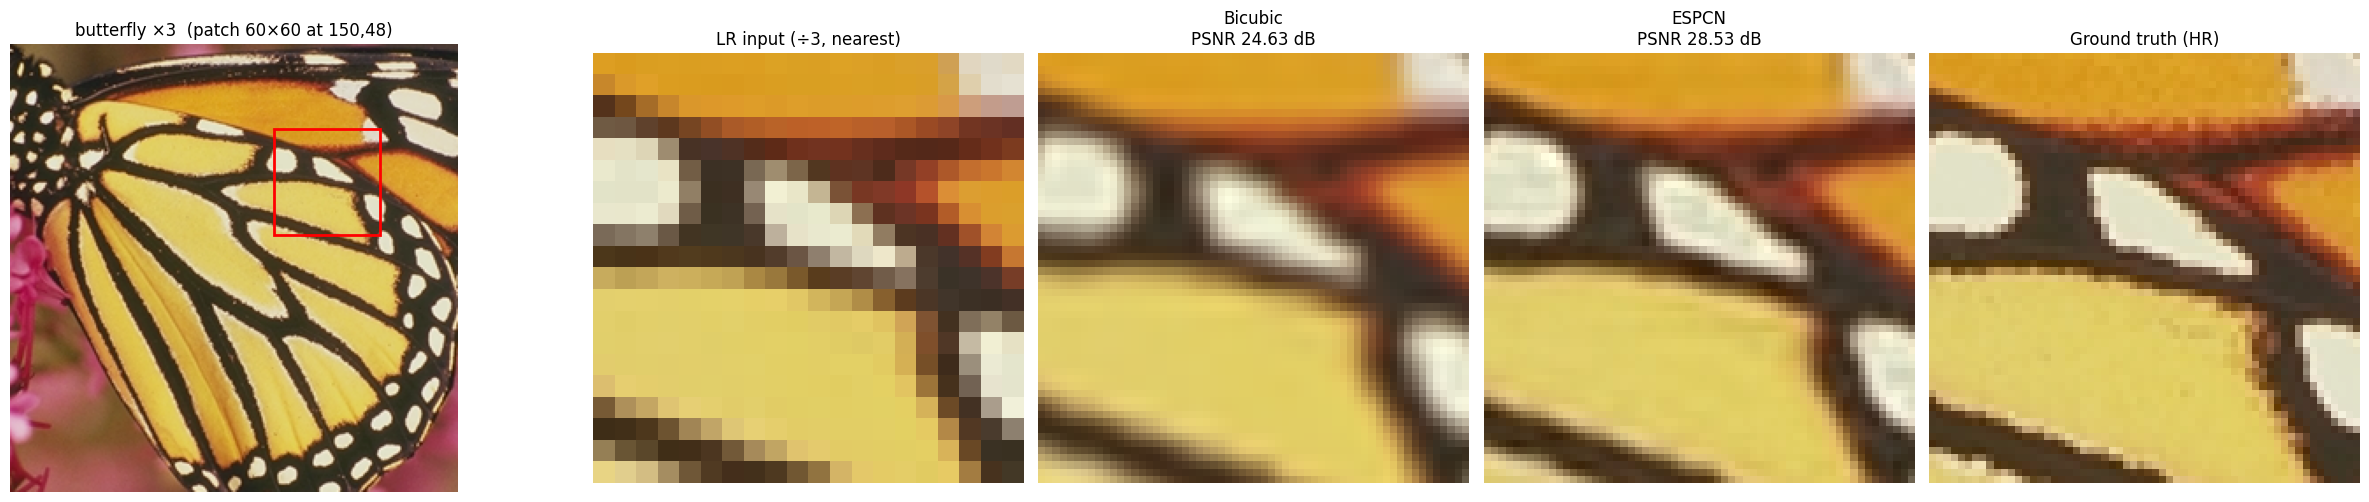

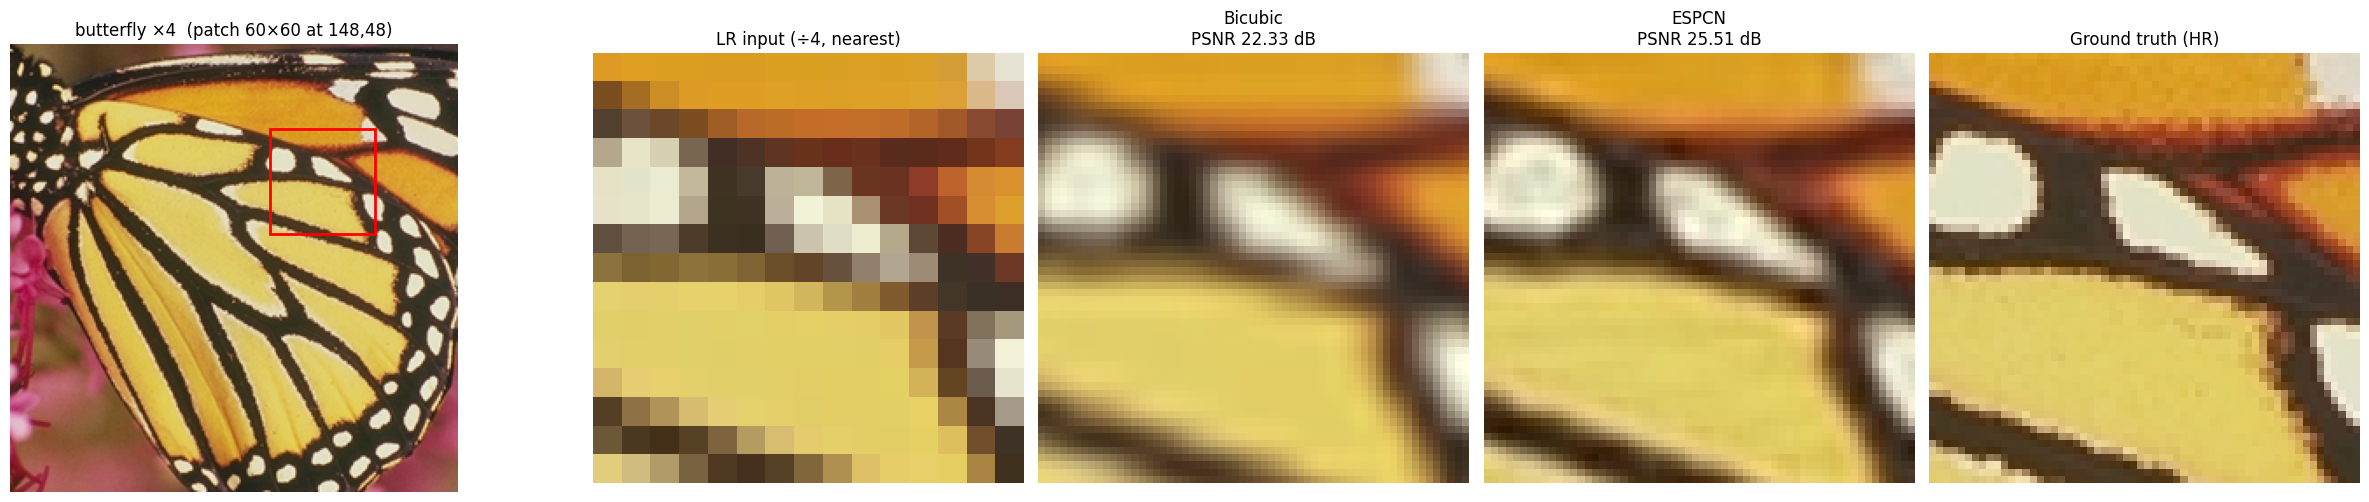

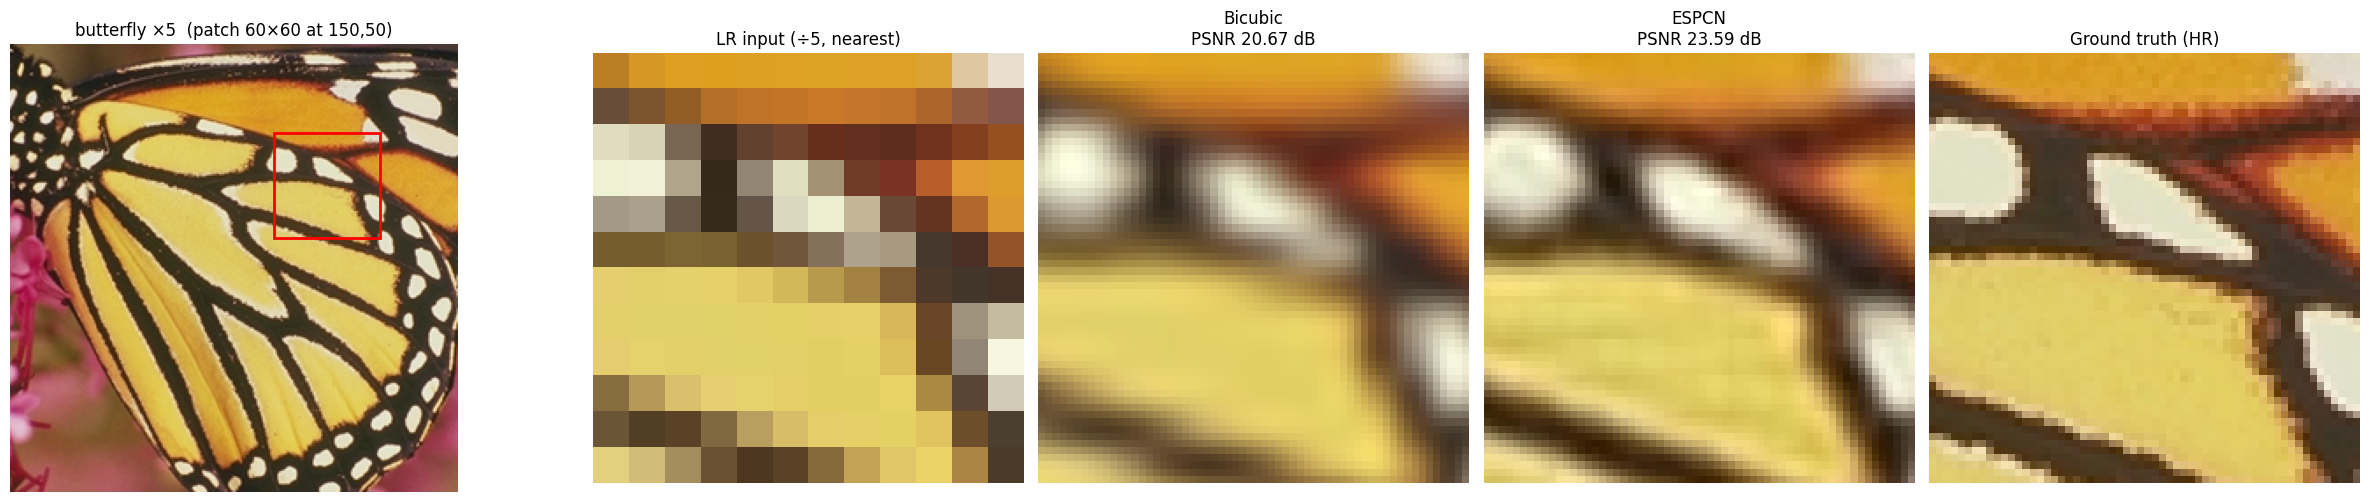

In [11]:
from matplotlib.patches import Rectangle

PATCH_IMAGE = 'butterfly'
PATCH_SCALES = [2, 3, 4, 5]
PATCH_BOX = (150 ,50, 60, 60)
PATCH_SIZE = 60


def auto_patch_box(img, size):
    y = rgb_to_y(img)
    gy, gx = np.gradient(y)
    energy = gx ** 2 + gy ** 2
    step = max(size // 4, 1)
    best, best_score = (0, 0), -1.0
    for top in range(0, y.shape[0] - size + 1, step):
        for left in range(0, y.shape[1] - size + 1, step):
            score = energy[top:top + size, left:left + size].mean()
            if score > best_score:
                best, best_score = (left, top), score
    return best[0], best[1], size, size


def snap_box(box, s, w, h):
    left, top, bw, bh = box
    left, top = (left // s) * s, (top // s) * s
    bw, bh = max((bw // s) * s, s), max((bh // s) * s, s)
    return left, top, min(bw, w - left), min(bh, h - top)


patch_path = next(
    (p for p in image_paths if PATCH_IMAGE and PATCH_IMAGE.lower() in os.path.basename(p).lower()),
    image_paths[0],
)
patch_name = os.path.splitext(os.path.basename(patch_path))[0]
patch_hr_full = Image.open(patch_path).convert("RGB")

base_box = PATCH_BOX if PATCH_BOX else auto_patch_box(patch_hr_full, PATCH_SIZE)
print(f"Image: {patch_name} | box (left, top, width, height): {base_box}")

for s in PATCH_SCALES:
    model = models.get(s)
    if model is None:
        print(f"[x{s}] checkpoint not found, skipping.")
        continue

    w, h = patch_hr_full.size
    w, h = w - w % s, h - h % s
    hr = patch_hr_full.crop((0, 0, w, h))
    lr = hr.resize((w // s, h // s), Image.BICUBIC)
    sr = espcn_upscale(model, lr, s)
    bicubic = lr.resize((w, h), Image.BICUBIC)

    left, top, bw, bh = snap_box(base_box, s, w, h)
    region = (left, top, left + bw, top + bh)
    lr_region = (left // s, top // s, (left + bw) // s, (top + bh) // s)

    hr_patch = hr.crop(region)
    y_hr_patch = rgb_to_y(hr_patch)
    panels = [
        (f"LR input (÷{s}, nearest)", lr.crop(lr_region).resize((bw, bh), Image.NEAREST)),
        ("Bicubic", bicubic.crop(region)),
        ("ESPCN", sr.crop(region)),
        ("Ground truth (HR)", hr_patch),
    ]

    fig, axes = plt.subplots(1, 5, figsize=(25, 5), gridspec_kw={"width_ratios": [1.6, 1, 1, 1, 1]})

    axes[0].imshow(hr)
    axes[0].add_patch(Rectangle((left, top), bw, bh, fill=False, edgecolor="red", linewidth=2))
    axes[0].set_title(f"{patch_name} ×{s}  (patch {bw}×{bh} at {left},{top})", fontsize=12)
    axes[0].axis("off")

    for ax, (title, im) in zip(axes[1:], panels):
        if title in ("Bicubic", "ESPCN"):
            psnr = peak_signal_noise_ratio(y_hr_patch, rgb_to_y(im), data_range=255)
            title = f"{title}\nPSNR {psnr:.2f} dB"
        ax.imshow(im, interpolation="nearest")
        ax.set_title(title, fontsize=12)
        ax.axis("off")

    plt.tight_layout()
    plt.show()